<center><h1>Hands-On Reinforcement Learning Applied to Trade Execution Algorithms</h1></center>
<center><h3>Taller de Aprendizaje por Refuerzo · Ejercicios 1 a 4</h3></center>
<center><b>Grupo:</b> Eneko Amezcua · Luis Coello · Eduardo González</center>
<center>Plantilla del taller (<i>execution_lab.ipynb</i>): Alberto Oteo García y Jesús Sanz del Real</center>

---

## Resumen

El notebook resuelve los cuatro ejercicios sobre un mismo simulador (`BestExecutionEnv`): una orden CARE de compra que se trocea en órdenes hijas de 1 título sobre bins de 5 segundos de Repsol.

| Ejercicio | Qué se hace | Bloques propios o modificados sobre la plantilla |
|---|---|---|
| 1 | Entorno completo y entrenamiento de un DDQN | `BestExecutionEnv` (TODO 1 a 13), `TWAP`, hiperparámetros y bucle de entrenamiento |
| 2 | Reward estilo TWAP y ajuste motivado de hiperparámetros | `EnvTWAP._compute_reward`, utilidades de evaluación, `optimal_q`, `train_agent` |
| 3 | Epsilon ligado al aprendizaje, no al nº de episodios | `adaptive_epsilon` |
| 4 | Idea B (90 % de la duración y volumen pendiente) e Idea C (parada, guardado y reanudación) | `EnvTWAP90`, `save_checkpoint`, `load_checkpoint`, `stop_and_checkpoint` |

**Convenciones.** El *VWAP slippage* se mide en puntos básicos (pb) y es positivo cuando el algoritmo compra más caro que el VWAP de mercado. Todas las semillas están fijadas y todos los agentes se evalúan sobre los mismos episodios.

## Datos

`rep_data.pkl` (Repsol): primera posición del libro (bid y ask) y volumen acumulado, agrupados cada 5 segundos entre las 13:00 y las 17:25. Train son los 60 primeros días hábiles de 2018; validación y test, los días 1 a 30 y 31 a 60 de 2019.

In [1]:
import os
import pickle
import warnings
from collections import deque
from pathlib import Path
from typing import Tuple

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"      # silencia los mensajes informativos de TensorFlow
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
import tensorflow as tf

tf.get_logger().setLevel("ERROR")

# Solo si `pip install -e .` no funciona: descomenta estas dos líneas
import sys
sys.path.append("..")

from src.agents.dqn import DDQNAgent
from src.report.report import plot_results

SEED = 42

def set_seed(seed=SEED):
    # Fija las semillas de Python, NumPy y TensorFlow
    tf.keras.utils.set_random_seed(seed)

set_seed()

# Estilo común de los gráficos
COLOR = {"ddqn": "#2a78d6", "twap": "#52514e", "alt": "#eb6834", "aux": "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "lines.linewidth": 2,
})

In [2]:
# Datos disponibles: san_data.pkl y rep_data.pkl
with open("../data/rep_data.pkl", "rb") as f:
    dict_ = pickle.load(f)

data = dict_["train"]

resumen = pd.DataFrame({
    split: {"días": len(dias), "bins por día (media)": int(np.mean([len(df) for df in dias.values()]))}
    for split, dias in dict_.items()
}).T
display(resumen)
display(next(iter(data.values())).head(3))

,días,bins por día (media)
train,60,3180
val,30,3180
test,30,3180


,ask1,bid1,vask1,vbid1,last,cumvol,date
time,,,,,,,
2018-01-02 13:00:00,15.00,14.995,1368.0,1878.0,15.000,1429424.0,2018-01-02
2018-01-02 13:00:05,15.01,15.005,1308.0,1.0,15.000,1430792.0,2018-01-02
2018-01-02 13:00:10,15.01,15.000,2988.0,5438.0,15.005,1431776.0,2018-01-02


---
# Ejercicio 1. Entorno y entrenamiento completo

## 1.1 Decisiones del entorno

| Bloque (TODO) | Decisión | Motivo |
|---|---|---|
| 1 y 2. Episodio | 400 a 600 bins; orden CARE del 7,5 % al 12,5 % de los bins; día y hora de inicio aleatorios | Con órdenes hijas de 1 título, toca una compra cada 8 a 13 bins. El agente ve días, horas, duraciones y tamaños distintos |
| 3. Estado | `[tiempo restante, volumen restante]`, ambos en [0, 1] | Normalizado: comparable entre órdenes de distinta duración y tamaño |
| 4 y 5. VWAP de mercado | El volumen de cada bin se valora al *mid* del bin anterior | No hay ejecuciones de mercado. El *mid* previo es el último precio conocido cuando se negocia ese volumen, y así no se usa información posterior |
| 6. Reward | `(VWAP_episodio − precio) / VWAP_episodio` al comprar; 0 si no se compra | Reward por defecto de la plantilla: premia comprar por debajo del VWAP |
| 7 a 9. Acciones | Comprar 1 título al `ask1`, o no hacer nada | Orden agresiva: se paga el ask. Antes de la primera compra el VWAP del algoritmo no existe (NaN, no 0) |
| 10 y 11. Fin | Se recorren todos los bins o se completa la orden | Las dos formas naturales de terminar una orden CARE |
| 12. *Done reward* | 0 | Este ejercicio no fija un objetivo final (se usa en el Ejercicio 4) |
| 13. Exploración | La acción aleatoria compra con probabilidad 0,10 | Es el ritmo medio de la orden (V/T ≈ 10 %), así que la exploración recorre el episodio entero. Con 50/50 la orden se agotaría en el primer 20 % y el resto de estados no se visitaría |

In [3]:
P_BUY_EXPLORE = 0.10    # (13) probabilidad de compra de la acción aleatoria


class BestExecutionEnv:

    def __init__(self, data, look_back=60):
        # Simulador del libro de órdenes para una orden CARE de compra.
        #  - data: diccionario {día: DataFrame} con los bins de 5 segundos.
        #  - look_back: ventana previa al episodio, disponible para construir features.
        # Fixed params
        self.data = data
        self.look_back = look_back
        self.episode_bins = None
        self.episode_full_len = None
        self.vol_care = None

        self.actions_fn = {
            0: self._do_nothing,
            1: self._agg_action,
        }

        self.n_actions = len(self.actions_fn)
        self.n_features = self._detect_num_feat()

        # Data variables
        self.episode = None
        self.episode_full = None

        # Env variables
        self.episode_vwap = None
        self.market_ep_vol = None
        self.state_pos = 0
        self.exec_vol = 0
        self.actions_hist = []
        self.algo_vwap_hist = []
        self.market_vwap_hist = []
        self.reward_hist = []
        self.price_hist = []
        self.vol_hist = []

    def _detect_num_feat(self):
        # Número de variables del estado (se adapta a observation_builder)
        self._reset_env_episode_params()
        self._generate_episode()
        s = self.observation_builder()
        return s.shape[0]

    def _reset_env_episode_params(self):
        # Las variables internas vuelven a sus valores iniciales
        self.episode_full_len = None
        self.episode = None
        self.episode_full = None
        self.episode_vwap = None
        self.market_ep_vol = None
        self.state_pos = 0
        self.algo_vwap = 0
        self.exec_vol = 0
        self.actions_hist = []
        self.algo_vwap_hist = []
        self.market_vwap_hist = []
        self.reward_hist = []
        self.price_hist = []
        self.vol_hist = []

    def _generate_episode_params(self):
        # (1) Características de la orden: duración y tamaño
        self.episode_bins = np.random.randint(400, 601)
        pct_bins = np.random.uniform(0.075, 0.125)
        self.vol_care = int(pct_bins * self.episode_bins)

        self.episode_full_len = self.episode_bins + self.look_back

        assert self.episode_bins <= 600
        assert self.episode_bins >= 400
        assert self.vol_care <= int(self.episode_bins * 0.125)
        assert self.vol_care >= int(self.episode_bins * 0.075)
        assert isinstance(self.vol_care, int)

    def _generate_episode(self):
        # (2) Día y hora en que comienza el episodio
        self._generate_episode_params()

        length_episode = 0
        while length_episode != self.episode_full_len:
            selected_day = np.random.choice(list(self.data.keys()))
            data_day = self.data[selected_day]
            init_time = np.random.choice(data_day.index)

            hour_pos = data_day.index.get_loc(init_time)
            initial_position = hour_pos - self.look_back
            final_position = hour_pos + self.episode_bins

            if initial_position < 0:
                continue
            else:
                self.episode_full = data_day.iloc[initial_position:final_position]
                self.episode = data_day.iloc[hour_pos:final_position]
                length_episode = self.episode_full.shape[0]

    def reset(self) -> np.array:
        # Nuevo episodio; devuelve la primera observación
        self._reset_env_episode_params()
        self._generate_episode()
        self._compute_episode_market_feat()

        return self.observation_builder()

    def observation_builder(self) -> np.array:
        # (3) Estado: tiempo restante y volumen restante, en tanto por uno
        time_left = (self.episode_bins - self.state_pos) / self.episode_bins
        vol_left = (self.vol_care - self.exec_vol) / self.vol_care
        obs = np.array([time_left, vol_left])

        return obs

    def _compute_episode_market_feat(self) -> Tuple[float, pd.Series]:
        # (4) VWAP de mercado y volumen de mercado del episodio.
        # Sin ejecuciones de mercado, el precio es el mid de cada bin.
        mid = (self.episode["ask1"] + self.episode["bid1"]) / 2
        self.market_ep_vol = self.episode["cumvol"].diff()
        self.market_ep_vol.iloc[0] = 0
        cum_vol = self.market_ep_vol.cumsum()
        # mid de cada bin por el volumen del bin siguiente
        self.episode_vwap = (
            (mid.values[:-1] * self.market_ep_vol.values[1:]).sum() / cum_vol.iloc[-1]
        )

        # Los mismos vectores, en NumPy, para el cálculo paso a paso (evita .iloc en cada step)
        self._mid = mid.values
        self._mkt_price = np.concatenate([[mid.values[0]], mid.values[:-1]])
        self._mkt_vol = self.market_ep_vol.values

        return self.episode_vwap, self.market_ep_vol

    def _compute_algo_vwap(self) -> float:
        # (8) VWAP del algoritmo hasta el step actual
        p_arr = np.array(self.price_hist)
        v_arr = np.array(self.vol_hist)
        algo_vwap = (p_arr * v_arr).sum() / v_arr.sum()
        return algo_vwap

    def _compute_reward(self, price: float, vol: float) -> float:
        # (6) Reward por defecto: distancia relativa del precio pagado al VWAP del episodio
        if vol == 0:
            reward = 0
            return reward
        reward = (self.episode_vwap - price) / self.episode_vwap
        return reward

    def _compute_stop_conditions(self) -> Tuple[bool, bool]:
        # (10) Condiciones de parada: tiempo agotado, orden completada
        is_bins_complete = self.state_pos >= self.episode_bins
        is_ord_complete = self.exec_vol >= self.vol_care
        return is_bins_complete, is_ord_complete

    def _compute_done_reward(self) -> float:
        # (12) Sin recompensa final en el entorno base
        done_reward = 0
        return done_reward

    def _agg_action(self) -> float:
        # (7) Compra agresiva de un título al ask1 del bin actual
        price = self.episode["ask1"].iloc[self.state_pos]
        self.price_hist.append(price)
        vol = 1
        self.exec_vol += vol
        self.vol_hist.append(vol)

        algo_vwap = self._compute_algo_vwap()
        self.algo_vwap_hist.append(algo_vwap)
        reward = self._compute_reward(price, vol)
        return reward

    def _do_nothing(self) -> float:
        # (9) No se compra: precio y volumen ejecutado = 0
        price = 0
        vol = 0
        self.price_hist.append(price)
        self.vol_hist.append(vol)
        # Sin compras previas no hay VWAP del algoritmo
        algo_vwap = self._compute_algo_vwap() if self.exec_vol > 0 else np.nan
        self.algo_vwap_hist.append(algo_vwap)
        reward = self._compute_reward(price, vol)

        return reward

    def _compute_market_vwap(self) -> float:
        # (5) VWAP de mercado hasta el step actual incluido
        p_arr = self._mkt_price[:self.state_pos + 1]
        v_arr = self._mkt_vol[:self.state_pos + 1]
        sum_vol = v_arr.sum()
        # Sin volumen de mercado hasta el step, se devuelve el último precio
        if sum_vol == 0:
            return self._mid[self.state_pos]
        market_vwap = (p_arr * v_arr).sum() / sum_vol
        return market_vwap

    def _compute_done(self) -> bool:
        # (11) El episodio termina si se cumple cualquiera de las condiciones
        conditions = self._compute_stop_conditions()
        is_bins_complete = conditions[0]
        is_ord_complete = conditions[1]
        done = is_bins_complete or is_ord_complete
        return done

    def step(self, action) -> Tuple[np.array, float, bool, dict]:
        # Evalúa la acción, calcula la recompensa y devuelve el nuevo estado
        market_vwap = self._compute_market_vwap()

        act_fn = self.actions_fn.get(action)
        if act_fn is None:
            raise ValueError(
                f"Invalid action {action}. Valid actions {self.actions_fn.keys()}"
            )

        reward = act_fn()

        self.market_vwap_hist.append(market_vwap)
        self.reward_hist.append(reward)

        self.state_pos += 1

        done = self._compute_done()

        if done:
            reward += self._compute_done_reward()
            return None, reward, done, {}

        observation = self.observation_builder()

        return np.array(observation), reward, done, {}

    def action_sample(self) -> int:
        # (13) Acción aleatoria: compra con probabilidad P_BUY_EXPLORE
        p = P_BUY_EXPLORE
        action = np.random.choice([0, 1], p=[1 - p, p])
        return action

    def stats_df(self):
        # Información para el gráfico de resultados de la ejecución
        my_df = pd.DataFrame(
            {"vwap": self.algo_vwap_hist, "vol": self.vol_hist},
            index=list(self.episode.index)[:len(self.algo_vwap_hist)]
        )
        my_df = my_df.reindex(self.episode.index)
        my_df["vol"] = my_df["vol"].fillna(0)
        my_df["vwap"] = my_df["vwap"].ffill()

        p = self.episode["ask1"]
        v = self.episode["cumvol"].diff().shift(-1)
        last_v = self.episode_full["cumvol"].diff().iloc[-1]
        v.iloc[-1] = last_v
        market_vwap = (p * v).cumsum() / v.cumsum()
        market_df = pd.DataFrame(
            {"vwap": market_vwap, "vol": v},
            index=v.index
        )

        mpx = (self.episode["ask1"] + self.episode["bid1"]) / 2

        return my_df, market_df, mpx

## 1.2 TWAP determinista

El TWAP reparte las compras a intervalos iguales. Con el estado elegido la regla es una línea: **comprar cuando el volumen restante es mayor o igual que el tiempo restante**. Sirve de referencia en todo el notebook.

In [4]:
class TWAP(DDQNAgent):
    def act(self, s):  # s = [tiempo restante, volumen restante]
        a = 1 if s[1] >= s[0] else 0
        return a

## 1.3 Agente y entrenamiento

Se usa el `DDQNAgent` de la plantilla: red primaria y red *target*, dos capas ocultas y *replay buffer* con la última experiencia siempre en el lote (CER). Los hiperparámetros son valores estándar; no se optimizan porque este ejercicio no fija un objetivo para el agente (se hace en el Ejercicio 2).

Orden del entrenamiento, el propio de un DQN con *replay*:

1. Se llena el buffer con experiencias de la política aleatoria.
2. En cada step: `act` → `step` → `experience`.
3. Cada 64 steps la red primaria aprende de un lote; cada 640, sus pesos se copian a la red *target*.
4. Al acabar cada episodio se reduce epsilon. El mínimo se alcanza al 90 % de los episodios, para terminar con una fase casi sin exploración.

In [5]:
# Agent Params
epsilon = 1.0
min_epsilon = 0.05
gamma = 0.99
alpha = 0.001
buffer_size = 50000
batch_size = 64
hidden_neurons = 32

# Training Params
nepisodes = 200
n_log = 25
epsilon_decay = (epsilon - min_epsilon) / (0.9 * nepisodes)
learn_after = batch_size
# Cada cuántos pasos se copian los pesos del primary al target
update_target_after = 10 * learn_after

set_seed()
env = BestExecutionEnv(data, 60)

agent = DDQNAgent(
    env,
    gamma=gamma,
    epsilon=epsilon,
    alpha=alpha,
    batch_size=batch_size,
    buffer_size=buffer_size,
    hidden_neurons=hidden_neurons
)

In [6]:
# Recolección de experiencias para el buffer. En este punto eps es 1 -> política aleatoria
s = env.reset()
for exps in range(buffer_size):
    a = agent.act(s)
    s1, r, done, _ = env.step(a)
    agent.experience(s, a, r, s1, done)
    s = s1
    if not exps % 10000:
        print(f'buffer exps: {exps}')
    if done:
        s = env.reset()

buffer exps: 0
buffer exps: 10000
buffer exps: 20000
buffer exps: 30000
buffer exps: 40000


In [7]:
# Entrenamiento
agent.set_trainable(True)
learn_counter = 0
history_steps = []
history_rewards = []
history_disc_rewards = []
history_losses = []
for episode in range(nepisodes):
    s = env.reset()
    step = 0
    cum_reward = 0
    dis_cum_reward = 0
    while True:
        a = agent.act(s)
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        learn_counter += 1
        cum_reward += r
        dis_cum_reward += agent.gamma ** step * r
        s = s1
        step += 1
        if not learn_counter % learn_after:
            mse = agent.learn()
        if not learn_counter % update_target_after:
            agent.update_target()
        if done:
            agent.epsilon = max([agent.epsilon - epsilon_decay, min_epsilon])
            history_rewards.append(cum_reward)
            history_disc_rewards.append(dis_cum_reward)
            history_losses.append(mse)
            history_steps.append(step)
            if not episode % n_log:
                print(
                    f'Episode: {episode}, '
                    f'steps: {np.round(np.mean(history_steps[-n_log:]), 2)}, '
                    f'rew: {np.round(np.mean(history_rewards[-n_log:]), 4)}, '
                    f'mse: {mse:.2e}, '
                    f'eps: {np.round(agent.epsilon, 2)}'
                )
            break

Episode: 0, steps: 445.0, rew: -0.0104, mse: 6.21e-05, eps: 0.99
Episode: 25, steps: 431.12, rew: -0.0041, mse: 8.87e-07, eps: 0.86
Episode: 50, steps: 310.04, rew: -0.0072, mse: 4.00e-06, eps: 0.73
Episode: 75, steps: 276.8, rew: -0.0016, mse: 1.44e-06, eps: 0.6
Episode: 100, steps: 174.12, rew: 0.0183, mse: 5.87e-07, eps: 0.47
Episode: 125, steps: 191.0, rew: -0.0344, mse: 3.46e-06, eps: 0.33
Episode: 150, steps: 150.08, rew: -0.0204, mse: 1.43e-06, eps: 0.2
Episode: 175, steps: 180.32, rew: 0.0007, mse: 9.93e-07, eps: 0.07


Orden ejecutada: 43 de 49 títulos en 471 de 471 bins


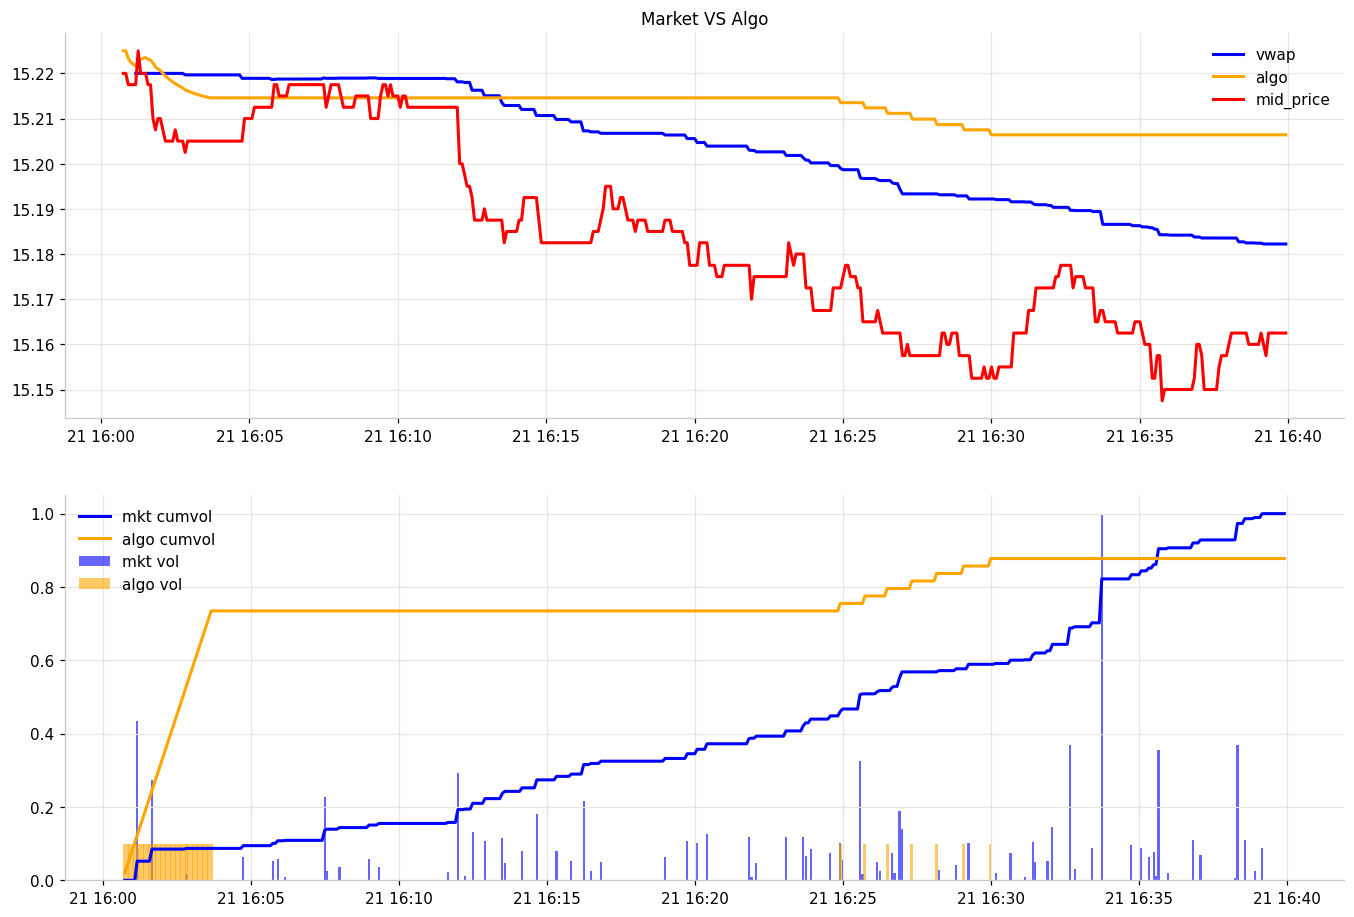

In [8]:
def play_episode(agent, env):
    # Ejecuta un episodio sin exploración y devuelve el entorno ya recorrido.
    # El agente fuerza la compra del primer bin consultando `agent.env`, así que
    # se le asigna el entorno que se está ejecutando.
    env_train, agent.env = agent.env, env
    agent.set_trainable(False)
    s = env.reset()
    done = False
    while not done:
        s, r, done, _ = env.step(agent.act(s))
    agent.env = env_train
    agent.set_trainable(True)
    return env


# Ejecución completa sobre un episodio de test
np.random.seed(SEED)
env_test = play_episode(agent, BestExecutionEnv(dict_["test"], 60))
plot_results(env_test)
print(f"Orden ejecutada: {env_test.exec_vol} de {env_test.vol_care} títulos "
      f"en {env_test.state_pos} de {env_test.episode_bins} bins")

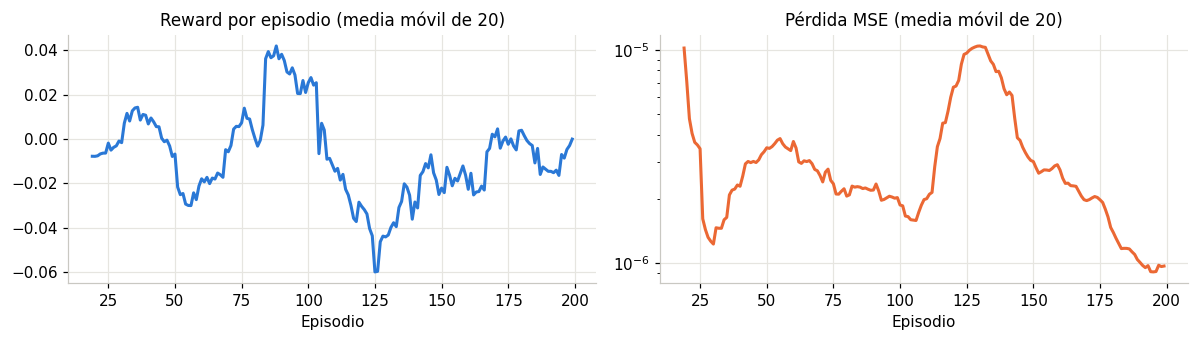

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
pd.Series(history_rewards).rolling(20).mean().plot(ax=axes[0], color=COLOR["ddqn"])
axes[0].set(title="Reward por episodio (media móvil de 20)", xlabel="Episodio")
pd.Series(history_losses).rolling(20).mean().plot(ax=axes[1], color=COLOR["alt"])
axes[1].set(title="Pérdida MSE (media móvil de 20)", xlabel="Episodio", yscale="log")
plt.tight_layout()
plt.show()

## 1.4 Lectura

El entorno, el entrenamiento y la ejecución funcionan de principio a fin. El patrón de compras no es interpretable, y es lo esperable: la reward por defecto no dice cuándo comprar ni obliga a completar la orden. Cada compra tiene además un valor esperado ligeramente negativo, porque se paga el ask frente a un VWAP calculado a *mid*. El Ejercicio 2 introduce el objetivo que falta.

---
# Ejercicio 2. Algoritmo de ejecución estilo TWAP

## 2.1 Estado

Se mantiene `[tiempo restante, volumen restante]`. Es suficiente para un TWAP: su calendario depende solo de cuánto tiempo y cuánto volumen quedan, así que el estado cumple la propiedad de Markov para este objetivo. No se añaden variables de mercado porque un TWAP no reacciona al precio.

## 2.2 Sistema de recompensas

El calendario se resume en una comparación: el agente va **retrasado** si `volumen restante ≥ tiempo restante`. El volumen restante se mide después de la acción del bin.

| Situación en el bin | Reward |
|---|---|
| No compra y va retrasado | −0,01 |
| No compra y va al día o adelantado | 0 |
| Compra y, aun así, sigue retrasado | término de precio + 0,005 |
| Compra y queda al día o adelantado | término de precio − 0,005 |

Por qué de aquí sale un TWAP:

- **Retrasarse cuesta 0,01 por bin.** Cuando el calendario alcanza al agente, comprar (−0,005) es mejor que esperar (−0,01).
- **Adelantarse no ahorra nada.** Cada compra hecha a tiempo o antes cuesta lo mismo (0,005). Con descuento, el agente prefiere pagar ese coste lo más tarde posible.
- Las dos fuerzas se cruzan justo en el calendario TWAP. Si el retraso supera un título, comprar pasa a premiarse (+0,005) y el agente recupera.
- **El término de precio** es el de la plantilla, `(VWAP − precio) / VWAP`. El estado no contiene precios, así que para el agente es ruido. Su tamaño se mide abajo para comprobar que no tapa la señal de calendario.

In [10]:
LATE_PENALTY = 0.01     # coste por bin de ir retrasado sin comprar
BUY_COST = 0.005        # coste (o premio, si sigue retrasado) asociado a cada compra


class EnvTWAP(BestExecutionEnv):
    # Entorno con reward estilo TWAP. `target` es la fracción de la duración
    # en la que debe completarse la orden (1.0 = TWAP sobre todo el episodio).
    target = 1.0

    def _time_left_plan(self) -> float:
        # Tiempo restante según el calendario objetivo
        horizon = self.target * self.episode_bins
        return max(horizon - self.state_pos, 0) / horizon

    def _compute_reward(self, price: float, vol: float) -> float:
        # --- Ejercicio 2: bloque modificado ---
        time_left = self._time_left_plan()
        vol_left = (self.vol_care - self.exec_vol) / self.vol_care   # ya incluye la compra del bin
        is_late = vol_left >= time_left
        if vol == 0:
            return -LATE_PENALTY if is_late else 0.0
        price_reward = (self.episode_vwap - price) / self.episode_vwap
        return price_reward + (BUY_COST if is_late else -BUY_COST)

In [11]:
# Magnitud del término de precio, medida con la política aleatoria sobre train
set_seed()
env_aux = EnvTWAP(data, 60)
price_terms = []
for _ in range(200):
    s = env_aux.reset()
    done = False
    while not done:
        a = 1 if env_aux.state_pos == 0 else env_aux.action_sample()
        if a == 1:
            ask = env_aux.episode["ask1"].iloc[env_aux.state_pos]
            price_terms.append((env_aux.episode_vwap - ask) / env_aux.episode_vwap)
        s, r, done, _ = env_aux.step(a)

PRICE_MEAN, PRICE_STD = np.mean(price_terms), np.std(price_terms)
print(f"Término de precio por compra ({len(price_terms)} compras): "
      f"media {PRICE_MEAN:+.5f}, desviación {PRICE_STD:.5f}")
print(f"Coste por compra {BUY_COST} = {BUY_COST / PRICE_STD:.1f} desviaciones; "
      f"penalización por retraso {LATE_PENALTY} = {LATE_PENALTY / PRICE_STD:.1f} desviaciones")

Término de precio por compra (9068 compras): media -0.00030, desviación 0.00150
Coste por compra 0.005 = 3.3 desviaciones; penalización por retraso 0.01 = 6.7 desviaciones


La señal de calendario es varias veces mayor que el ruido del precio, y todas las recompensas por step quedan muy dentro de [−1, 1].

## 2.3 Cómo se mide el parecido con un TWAP

**Desvío respecto al calendario**: media, a lo largo del episodio, de |fracción ejecutada − fracción planificada|. Vale 0 con el calendario exacto y en torno a 0,45 o 0,5 si se compra todo al principio o no se compra.

Como el estado no contiene mercado, la secuencia de compras de una política sin exploración depende solo de la duración T y del tamaño V de la orden. Eso permite:

- calcular las trayectorias en lote, con una llamada a la red por bin para todas las órdenes a la vez;
- medir el desvío sin ruido muestral sobre un **panel fijo de 15 órdenes** que cubre todo el rango de duraciones (400 a 600 bins) y tamaños (7,5 % a 12,5 %).

El mercado solo interviene en el *VWAP slippage*, que se calcula con los precios ask de los bins en los que se compra.

In [12]:
def rollout_schedules(policy, T, V):
    # Compras de una política sin exploración para N órdenes de duración T[i] y tamaño V[i].
    # Reproduce la dinámica del entorno: estado [tiempo restante, volumen restante],
    # primer bin con compra forzada (como DDQNAgent.act) y fin por tiempo o por orden completa.
    T, V = np.asarray(T), np.asarray(V)
    buys = np.zeros((len(T), int(T.max())), dtype=bool)
    exec_vol = np.zeros(len(T), dtype=int)
    for pos in range(int(T.max())):
        active = (pos < T) & (exec_vol < V)
        if not active.any():
            break
        states = np.column_stack([(T - pos) / T, (V - exec_vol) / V])[active]
        actions = np.ones(len(states), dtype=int) if pos == 0 else np.asarray(policy(states))
        buys[active, pos] = actions == 1
        exec_vol[active] += actions
    return buys


def greedy_policy(agent):
    # Política sin exploración del agente: acción de mayor Q
    return lambda states: agent.getQs(states, agent.primary_model).argmax(axis=1)


def twap_policy(target=1.0):
    # Regla TWAP vectorizada; con target < 1 el calendario se comprime a esa fracción del episodio
    return lambda states: (
        states[:, 1] >= np.maximum(states[:, 0] - (1 - target), 0) / target
    ).astype(int)


def schedule_metrics(buys, T, V, target=1.0):
    # Métricas de calendario por orden
    T, V = np.asarray(T), np.asarray(V)
    t = np.arange(1, buys.shape[1] + 1)[None, :]
    in_episode = t <= T[:, None]
    done_frac = buys.cumsum(axis=1) / V[:, None]
    plan_frac = np.minimum(t / (target * T[:, None]), 1.0)
    last_buy = np.where(buys.any(axis=1), buys.shape[1] - buys[:, ::-1].argmax(axis=1), 0)
    return pd.DataFrame({
        "T": T, "V": V,
        "desvio": (np.abs(done_frac - plan_frac) * in_episode).sum(axis=1) / T,
        "completado": buys.sum(axis=1) / V,
        "tiempo_usado": last_buy / T,
    })


# Panel fijo: 5 duraciones x 3 tamaños
PANEL_T = np.repeat([400, 450, 500, 550, 600], 3)
PANEL_V = (PANEL_T * np.tile([0.075, 0.10, 0.125], 5)).astype(int)

def panel_deviation(policy, target=1.0):
    # Desvío medio y fracción de órdenes completadas sobre el panel
    m = schedule_metrics(rollout_schedules(policy, PANEL_T, PANEL_V), PANEL_T, PANEL_V, target)
    return m["desvio"].mean(), (m["completado"] >= 1).mean()


def sample_episodes(data, n, seed):
    # Muestra n episodios (día, hora, duración y tamaño) sin alterar el generador aleatorio global.
    # La misma muestra se reutiliza para todos los agentes: comparación pareada.
    rng_state = np.random.get_state()
    np.random.seed(seed)
    env, episodes = BestExecutionEnv(data, 60), []
    for _ in range(n):
        env.reset()
        episodes.append({
            "T": env.episode_bins, "V": env.vol_care, "index": env.episode.index,
            "ask": env.episode["ask1"].values, "vwap": env.episode_vwap,
        })
    np.random.set_state(rng_state)
    return episodes


def evaluate(policy, episodes, target=1.0):
    # Métricas de calendario y VWAP slippage (pb; positivo = se compra más caro que el mercado)
    T = np.array([e["T"] for e in episodes])
    V = np.array([e["V"] for e in episodes])
    buys = rollout_schedules(policy, T, V)
    m = schedule_metrics(buys, T, V, target)
    m["slippage_pb"] = [
        (e["ask"][b[:e["T"]]].mean() - e["vwap"]) / e["vwap"] * 1e4 for e, b in zip(episodes, buys)
    ]
    return m, buys


def mean_trajectory(buys, T, V, grid):
    # Fracción media de la orden ejecutada en cada punto del tiempo normalizado del episodio
    acc = np.zeros(len(grid))
    for b, t, v in zip(buys, T, V):
        done_frac = np.concatenate([[0], b[:t].cumsum() / v])
        acc += done_frac[np.minimum((grid * t).astype(int), t)]
    return acc / len(buys)


def dev_axis(ax):
    # Eje logarítmico común para todas las curvas de desvío
    ax.set_yscale("log")
    ax.set_yticks([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5])
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.3g"))
    ax.minorticks_off()
    ax.set_ylim(0.004, 0.6)


def legend_below(fig, ax, ncol=3):
    # Leyenda única bajo la figura
    handles, labels = ax.get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0.09, 1, 1))
    fig.legend(handles, labels, loc="lower center", ncol=ncol)


DEV_TWAP = panel_deviation(twap_policy())[0]
DEV_WORST = panel_deviation(lambda states: np.zeros(len(states), dtype=int))[0]
print(f"Desvío en el panel: TWAP determinista {DEV_TWAP:.3f} | no comprar {DEV_WORST:.3f} | "
      f"comprar siempre {panel_deviation(lambda states: np.ones(len(states), dtype=int))[0]:.3f}")

Desvío en el panel: TWAP determinista 0.009 | no comprar 0.480 | comprar siempre 0.450


In [13]:
# Comprobación: el cálculo en lote da las mismas compras que recorrer el entorno con env.step
set_seed()
env_check = EnvTWAP(data, 60)
for name, ag, pol in [("TWAP", TWAP(env_check), twap_policy()),
                      ("DDQN del Ejercicio 1", agent, greedy_policy(agent))]:
    iguales = 0
    for _ in range(5):
        play_episode(ag, env_check)
        en_lote = rollout_schedules(pol, [env_check.episode_bins], [env_check.vol_care])[0]
        iguales += np.array_equal(np.array(env_check.vol_hist), en_lote[:len(env_check.vol_hist)].astype(int))
    print(f"{name}: {iguales} de 5 episodios idénticos")

TWAP: 5 de 5 episodios idénticos
DDQN del Ejercicio 1: 5 de 5 episodios idénticos


El desvío del TWAP determinista no es 0 porque la orden es discreta: avanza a escalones de un título. Ese valor es el nivel de referencia para el agente.

## 2.4 Segunda parte: hiperparámetros

### Gamma

Cualquier política que nunca se retrase paga el mismo total sin descuento (0,005 por título, más el precio). **Con gamma = 1 el agente es indiferente entre un TWAP y comprar todo al principio**; es el descuento lo que rompe el empate. Además, la reward es densa: la consecuencia de cada decisión llega en el mismo bin, así que no hace falta un horizonte largo.

Para elegir gamma se calcula la política óptima exacta. El estado es (bin, títulos comprados) y la transición es determinista, así que Q* sale por inducción hacia atrás. Con Q* se mide la **ventaja de la acción TWAP**: cuánto mejor es, en Q, seguir el calendario que desviarse. Esa ventaja es la señal que la red tiene que distinguir del ruido del precio.

In [14]:
def optimal_q(T, V, gamma, target=1.0, kappa=0.0):
    # Q* exacto por inducción hacia atrás para una orden (T, V) con la reward de EnvTWAP.
    # El término de precio entra por su media, porque el estado no lo observa.
    # kappa: penalización final por volumen pendiente (se usa en el Ejercicio 4).
    Q = np.zeros((T + 1, V + 1, 2))
    best = np.zeros((T + 1, V + 1))
    horizon = target * T
    for t in range(T - 1, -1, -1):
        time_left = max(horizon - t, 0) / horizon
        last_bin = t + 1 >= T
        for k in range(V):
            # Acción 0: no comprar
            r = -LATE_PENALTY if (V - k) / V >= time_left else 0.0
            Q[t, k, 0] = r + (-kappa * (V - k) / V if last_bin else gamma * best[t + 1, k])
            # Acción 1: comprar
            r = PRICE_MEAN + (BUY_COST if (V - k - 1) / V >= time_left else -BUY_COST)
            ends = last_bin or k + 1 >= V
            Q[t, k, 1] = r + (-kappa * (V - k - 1) / V if ends else gamma * best[t + 1, k + 1])
            best[t, k] = Q[t, k].max()
    return Q


def twap_advantage(Q, T, V, target=1.0):
    # Ventaja en Q de la acción TWAP frente a la contraria, a lo largo de la trayectoria TWAP
    horizon, k, adv = target * T, 0, []
    for t in range(T):
        if k >= V:
            break
        a = 1 if (t == 0 or (V - k) / V >= max(horizon - t, 0) / horizon) else 0
        adv.append(Q[t, k, a] - Q[t, k, 1 - a])
        k += a
    return np.array(adv)


T_REF, V_REF = 500, 50      # orden central del rango
rows, ratio = [], {}
for g in [1.0, 0.99, 0.95, 0.9, 0.8, 0.5, 0.0]:
    adv = twap_advantage(optimal_q(T_REF, V_REF, g), T_REF, V_REF)
    ratio[g] = adv.min() / PRICE_STD
    rows.append({
        "gamma": f"{g:g}",
        "horizonte efectivo (bins)": "∞" if g == 1 else round(1 / (1 - g)),
        "ventaja mediana": np.median(adv),
        "ventaja mínima": adv.min(),
        "ventaja mínima / ruido": ratio[g],
    })
display(pd.DataFrame(rows).set_index("gamma").style.format({
    "ventaja mediana": "{:.5f}", "ventaja mínima": "{:.5f}", "ventaja mínima / ruido": "{:.2f}"}))

# Criterio: el mayor gamma cuya ventaja mínima supera el ruido de la reward
GAMMA = max(g for g in ratio if ratio[g] > 1)
print(f"Gamma elegido: {GAMMA}")

,horizonte efectivo (bins),ventaja mediana,ventaja mínima,ventaja mínima / ruido
gamma,,,,
1,∞,0.00000,0.00000,0.00
0.99,100,0.00031,0.00005,0.04
0.95,20,0.00140,0.00026,0.18
0.9,10,0.00248,0.00053,0.35
0.8,5,0.00391,0.00106,0.71
0.5,2,0.00521,0.00265,1.76
0,1,0.00530,0.00470,3.13


Gamma elegido: 0.5


Con gamma = 0,99 la ventaja de la acción correcta es una fracción del ruido: el agente puede aprender el calendario, pero la señal es débil y la política oscila. La ventaja crece al bajar gamma. **Criterio: el mayor gamma cuya ventaja mínima supera el ruido de la reward, que resulta ser 0,5.** No se baja más porque gamma = 0 anula cualquier señal futura, y el Ejercicio 4 necesita que la penalización final se propague unos bins hacia atrás.

El criterio se contrasta más abajo entrenando también con gamma = 0,99.

### Resto de hiperparámetros

| Parámetro | Valor | Motivo |
|---|---|---|
| `buffer_size` | 30.000 | Unos 60 episodios: mezcla días y órdenes distintos (independencia) sin conservar experiencias de políticas ya superadas (obsolescencia). Se llena con exploración aleatoria antes de entrenar |
| `alpha` | 0,0005 | Los *targets* son del orden de 0,01 y llevan ruido: pasos pequeños para que la política sea estable |
| `hidden_neurons` | 32 | La regla TWAP es una frontera lineal en dos variables; no hace falta más capacidad |
| `batch_size`, `learn_after`, `update_target_after` | 64, 64, 640 | Valores de la plantilla: un aprendizaje cada 64 steps y copia a la red *target* cada 10 aprendizajes |
| `nepisodes` | 300 | Unos 140.000 steps y 2.200 aprendizajes. El desvío se estabiliza mucho antes (figura) |
| `epsilon` | 1 → 0,05 lineal, con el mínimo al 90 % de los episodios | Exploración total al principio y una fase final casi sin exploración |

El bucle de entrenamiento es el del Ejercicio 1, encapsulado en funciones para reutilizarlo. Cada 25 episodios se mide el desvío de la política sin exploración sobre el panel.

In [15]:
ALPHA = 0.0005
BUFFER_SIZE = 30000
BATCH_SIZE = 64
HIDDEN_NEURONS = 32
NEPISODES = 300
EPS_MIN = 0.05
LEARN_AFTER = BATCH_SIZE
UPDATE_TARGET_AFTER = 10 * LEARN_AFTER
EVAL_EVERY = 25


def make_agent(env, gamma):
    return DDQNAgent(env, gamma=gamma, epsilon=1.0, alpha=ALPHA, batch_size=BATCH_SIZE,
                     buffer_size=BUFFER_SIZE, hidden_neurons=HIDDEN_NEURONS)


def fill_buffer(agent, env):
    # Llena el buffer con la política aleatoria (epsilon = 1)
    s = env.reset()
    for _ in range(agent.buffer_size):
        a = agent.act(s)
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        s = env.reset() if done else s1


def run_episode(agent, env, state):
    # Un episodio de entrenamiento, con el mismo orden de interacción que en el Ejercicio 1
    s = env.reset()
    cum_reward, loss, done = 0.0, np.nan, False
    while not done:
        a = agent.act(s)
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        state["steps"] += 1
        cum_reward += r
        s = s1
        if not state["steps"] % LEARN_AFTER:
            loss = agent.learn()
            state["updates"] += 1
        if not state["steps"] % UPDATE_TARGET_AFTER:
            agent.update_target()
    return cum_reward, loss


def new_state():
    # Todo lo que describe el punto en que está un entrenamiento
    return {"episode": 0, "steps": 0, "updates": 0, "rewards": [], "losses": [],
            "epsilons": [], "eval_episode": [], "dev": [], "completed": []}


def train_agent(agent, env, n_episodes, update_epsilon, target=1.0, state=None, on_eval=None):
    # update_epsilon(agent, state, dev): regla de exploración; dev es None salvo en los episodios con medida.
    # on_eval(agent, state): se llama tras cada medida; si devuelve True, el entrenamiento se detiene.
    state = new_state() if state is None else state
    agent.set_trainable(True)
    while state["episode"] < n_episodes:
        state["epsilons"].append(agent.epsilon)
        cum_reward, loss = run_episode(agent, env, state)
        state["episode"] += 1
        state["rewards"].append(cum_reward)
        state["losses"].append(loss)

        dev = None
        if state["episode"] % EVAL_EVERY == 0:
            dev, completed = panel_deviation(greedy_policy(agent), target)
            state["eval_episode"].append(state["episode"])
            state["dev"].append(dev)
            state["completed"].append(completed)

        update_epsilon(agent, state, dev)

        if dev is not None:
            if state["episode"] % (2 * EVAL_EVERY) == 0:
                print(f"Episodio {state['episode']:3d} | desvío {dev:.3f} | órdenes completas {completed:.0%} | "
                      f"epsilon {agent.epsilon:.2f} | pérdida {np.nanmean(state['losses'][-EVAL_EVERY:]):.1e}")
            if on_eval is not None and on_eval(agent, state):
                break
    return state


def linear_epsilon(n_episodes):
    # Decay lineal por episodio, con el mínimo al 90 % del entrenamiento
    decay = (1.0 - EPS_MIN) / (0.9 * n_episodes)
    def rule(agent, state, dev):
        agent.epsilon = max(agent.epsilon - decay, EPS_MIN)
    return rule

In [16]:
set_seed()
env2 = EnvTWAP(data, 60)
agent2 = make_agent(env2, GAMMA)
fill_buffer(agent2, env2)
hist2 = train_agent(agent2, env2, NEPISODES, linear_epsilon(NEPISODES))
print(f"Total: {hist2['steps']:,} steps y {hist2['updates']:,} aprendizajes")

Episodio  50 | desvío 0.025 | órdenes completas 100% | epsilon 0.82 | pérdida 3.9e-06
Episodio 100 | desvío 0.013 | órdenes completas 100% | epsilon 0.65 | pérdida 2.5e-06
Episodio 150 | desvío 0.008 | órdenes completas 100% | epsilon 0.47 | pérdida 2.7e-06
Episodio 200 | desvío 0.009 | órdenes completas 100% | epsilon 0.30 | pérdida 1.7e-06
Episodio 250 | desvío 0.008 | órdenes completas 100% | epsilon 0.12 | pérdida 1.4e-06
Episodio 300 | desvío 0.008 | órdenes completas 100% | epsilon 0.05 | pérdida 1.7e-06
Total: 143,035 steps y 2,234 aprendizajes


In [17]:
# Contraste del criterio de gamma: mismo entrenamiento y misma semilla, con gamma = 0.99
set_seed()
env2_g99 = EnvTWAP(data, 60)
agent2_g99 = make_agent(env2_g99, 0.99)
fill_buffer(agent2_g99, env2_g99)
hist2_g99 = train_agent(agent2_g99, env2_g99, NEPISODES, linear_epsilon(NEPISODES))

Episodio  50 | desvío 0.059 | órdenes completas 100% | epsilon 0.82 | pérdida 3.3e-06
Episodio 100 | desvío 0.062 | órdenes completas 100% | epsilon 0.65 | pérdida 7.1e-06
Episodio 150 | desvío 0.010 | órdenes completas 100% | epsilon 0.47 | pérdida 4.4e-06
Episodio 200 | desvío 0.037 | órdenes completas 100% | epsilon 0.30 | pérdida 2.0e-06
Episodio 250 | desvío 0.022 | órdenes completas 100% | epsilon 0.12 | pérdida 1.0e-06
Episodio 300 | desvío 0.050 | órdenes completas 100% | epsilon 0.05 | pérdida 4.7e-07


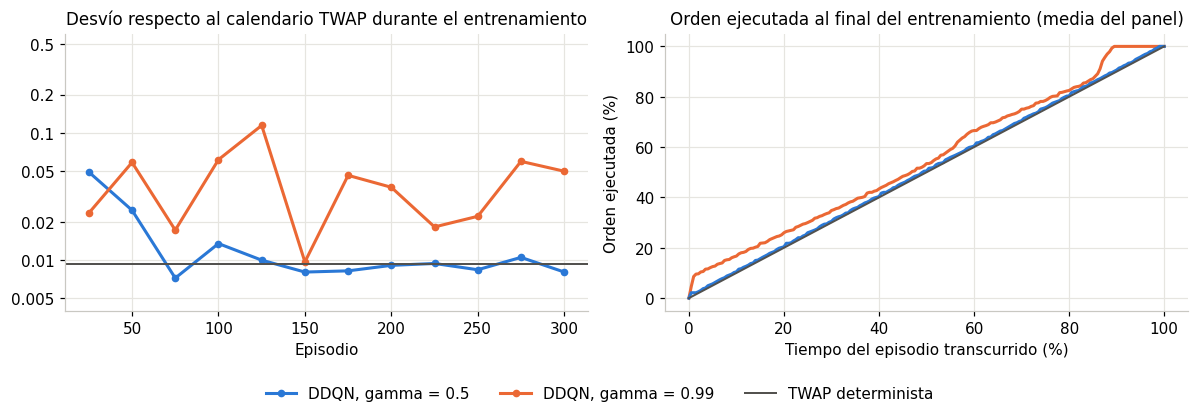

Desvío medio en las 4 últimas medidas: gamma = 0.5: 0.009 | gamma = 0.99: 0.037 | TWAP determinista: 0.009


In [18]:
grid = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(hist2["eval_episode"], hist2["dev"], color=COLOR["ddqn"], marker="o", ms=4, label=f"DDQN, gamma = {GAMMA}")
axes[0].plot(hist2_g99["eval_episode"], hist2_g99["dev"], color=COLOR["alt"], marker="o", ms=4, label="DDQN, gamma = 0.99")
axes[0].axhline(DEV_TWAP, color=COLOR["twap"], lw=1.3, label="TWAP determinista")
axes[0].set(title="Desvío respecto al calendario TWAP durante el entrenamiento", xlabel="Episodio")
dev_axis(axes[0])
for ag, color in [(agent2_g99, COLOR["alt"]), (agent2, COLOR["ddqn"])]:
    traj = mean_trajectory(rollout_schedules(greedy_policy(ag), PANEL_T, PANEL_V), PANEL_T, PANEL_V, grid)
    axes[1].plot(grid * 100, traj * 100, color=color)
axes[1].plot(grid * 100, grid * 100, color=COLOR["twap"], lw=1.3)
axes[1].set(title="Orden ejecutada al final del entrenamiento (media del panel)",
            xlabel="Tiempo del episodio transcurrido (%)", ylabel="Orden ejecutada (%)")
legend_below(fig, axes[0])
plt.show()

ultimos = lambda h: np.mean(h["dev"][-4:])
print(f"Desvío medio en las 4 últimas medidas: gamma = {GAMMA}: {ultimos(hist2):.3f} | "
      f"gamma = 0.99: {ultimos(hist2_g99):.3f} | TWAP determinista: {DEV_TWAP:.3f}")

El desvío es la métrica del objetivo. La reward acumulada no sirve para comparar políticas: solo penaliza el retraso, así que un agente que se adelanta al calendario obtiene la misma reward que un TWAP. Es el empate que rompe el descuento.

## 2.5 Resultados en train

El requisito es que el algoritmo funcione para distintos días, horas, duraciones y tamaños. Se comprueba de dos formas: con métricas sobre 300 episodios de train, desglosadas por duración y tamaño, y con gráficos de episodios concretos.

In [19]:
episodes_train = sample_episodes(data, 300, seed=2024)
m2, buys2 = evaluate(greedy_policy(agent2), episodes_train)
m_twap_train, buys_twap_train = evaluate(twap_policy(), episodes_train)

resumen2 = pd.DataFrame({
    "DDQN (Ejercicio 2)": m2[["desvio", "tiempo_usado", "slippage_pb"]].mean(),
    "TWAP determinista": m_twap_train[["desvio", "tiempo_usado", "slippage_pb"]].mean(),
}).T
resumen2["órdenes completas"] = [(m2["completado"] >= 1).mean(), (m_twap_train["completado"] >= 1).mean()]
display(resumen2.style.format({"desvio": "{:.3f}", "tiempo_usado": "{:.1%}",
                               "slippage_pb": "{:+.2f}", "órdenes completas": "{:.0%}"}))

# Desvío del DDQN por duración y tamaño relativo de la orden
m2["duración (bins)"] = pd.cut(m2["T"], [399, 466, 533, 600], labels=["400-466", "467-533", "534-600"])
m2["tamaño (V/T)"] = pd.cut(m2["V"] / m2["T"], [0.07, 0.0917, 0.1083, 0.126], labels=["7,5-9,2 %", "9,2-10,8 %", "10,8-12,5 %"])
display(m2.pivot_table(index="duración (bins)", columns="tamaño (V/T)", values="desvio", aggfunc="mean")
          .style.format("{:.3f}").set_caption("Desvío medio del DDQN por duración y tamaño (train)"))

,desvio,tiempo_usado,slippage_pb,órdenes completas
DDQN (Ejercicio 2),0.008,98.3%,+2.27,100%
TWAP determinista,0.009,98.2%,+2.27,100%


tamaño (V/T),"7,5-9,2 %","9,2-10,8 %","10,8-12,5 %"
duración (bins),,,
400-466,0.011,0.009,0.007
467-533,0.009,0.007,0.006
534-600,0.008,0.006,0.005


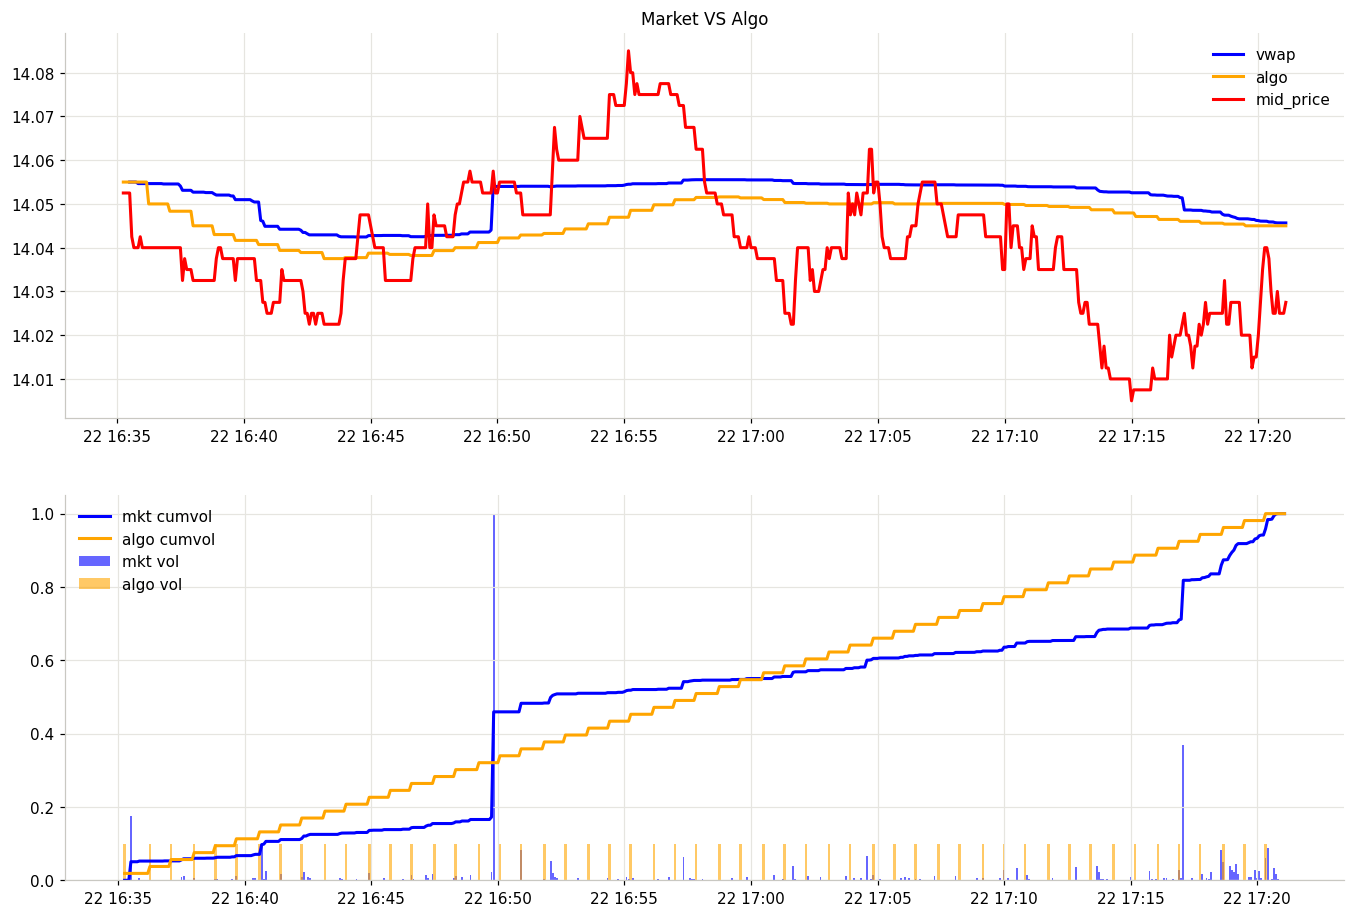

In [20]:
# Un episodio de train con el gráfico de la plantilla (comparable con images/twap_model/twap_reproduction_dqn.png)
np.random.seed(7)
env2_plot = play_episode(agent2, EnvTWAP(data, 60))
plot_results(env2_plot)

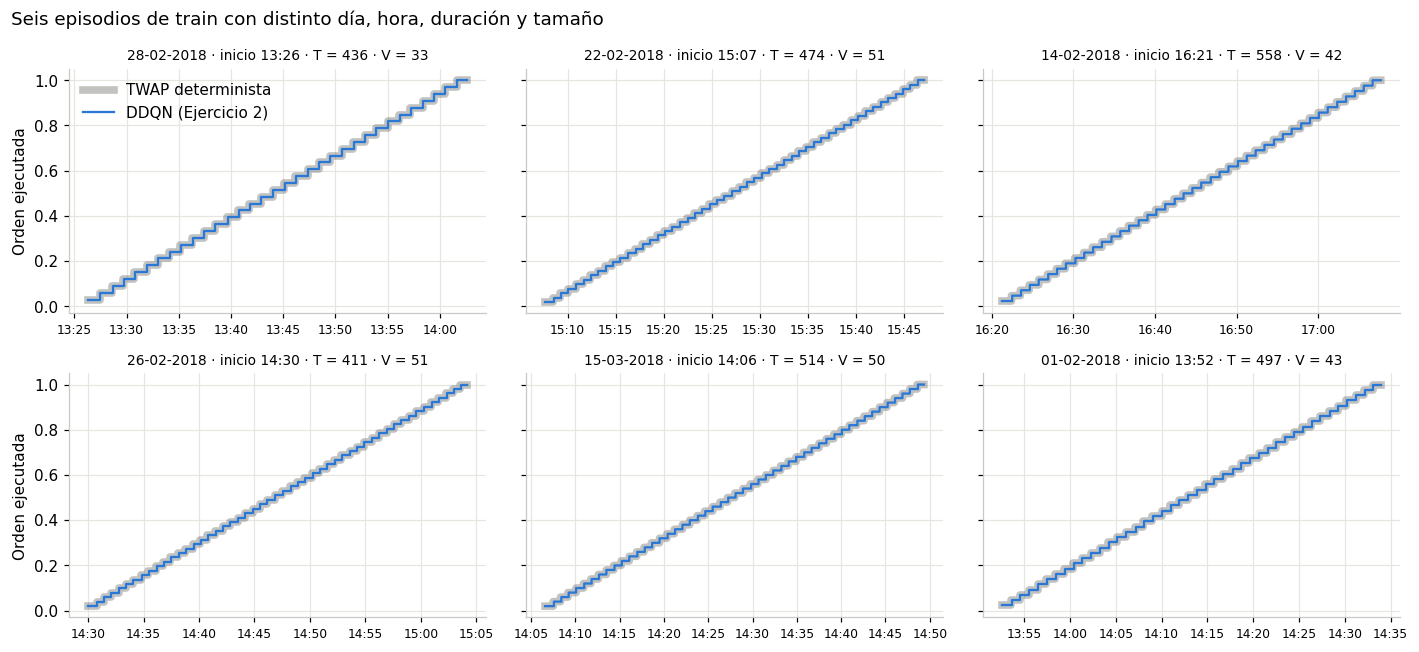

In [21]:
def plot_schedules(episodes, name, buys, ref_name, ref_buys, title="", n=6):
    # Fracción de la orden ejecutada en n episodios: el agente (línea fina) sobre la referencia (banda tenue)
    fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
    for i, ax in enumerate(axes.ravel()[:n]):
        e = episodes[i]
        ax.step(e["index"], ref_buys[i, :e["T"]].cumsum() / e["V"], where="post", color=COLOR["twap"],
                lw=5, alpha=0.35, label=ref_name)
        ax.step(e["index"], buys[i, :e["T"]].cumsum() / e["V"], where="post", color=COLOR["ddqn"], lw=1.5, label=name)
        ax.set_title(f"{e['index'][0]:%d-%m-%Y} · inicio {e['index'][0]:%H:%M} · T = {e['T']} · V = {e['V']}", fontsize=9)
        ax.tick_params(axis="x", labelsize=8)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    axes[0, 0].legend(loc="upper left")
    for ax in axes[:, 0]:
        ax.set_ylabel("Orden ejecutada")
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    plt.tight_layout()
    plt.show()


plot_schedules(episodes_train, "DDQN (Ejercicio 2)", buys2, "TWAP determinista", buys_twap_train,
               title="Seis episodios de train con distinto día, hora, duración y tamaño")

## 2.6 Lectura

- El agente reproduce el calendario TWAP: completa las órdenes, usa prácticamente toda la duración y su desvío es del orden del que tiene el TWAP determinista por la discretización.
- El comportamiento se mantiene en todo el rango de duraciones y tamaños, y en días y horas distintos.
- El *slippage* coincide con el del TWAP, como corresponde a una réplica: sin información de mercado en el estado no hay forma de mejorar el precio.
- El contraste con gamma = 0,99 respalda el criterio: con la ventaja de la acción por debajo del ruido, el desvío es mayor y menos estable.

---
# Ejercicio 3. Exploración ligada al aprendizaje

El decay lineal fija de antemano cuánto se explora en cada episodio, aprenda o no el agente. Aquí epsilon pasa a depender de lo que el agente ha conseguido.

**¿Cómo se determina que el agente ha mejorado?** Cada 25 episodios se mide el desvío de su política sin exploración sobre el panel fijo. Se compara con dos referencias: el **nivel de aspiración**, que es el desvío del TWAP determinista, y el **peor caso**, que es no comprar.

**¿Cómo se traslada a epsilon?** Epsilon es proporcional a la distancia que le queda al agente hasta el nivel de aspiración:

$$\text{gap} = \frac{\text{desvío} - \text{desvío}_{TWAP}}{\text{desvío}_{peor} - \text{desvío}_{TWAP}} \in [0, 1] \qquad \epsilon_{objetivo} = \epsilon_{min} + (1 - \epsilon_{min}) \cdot \text{gap}$$

El valor se suaviza con una media móvil exponencial (β = 0,5) para no reaccionar a una sola medida.

Propiedades de la regla:

- **No depende del nº de episodios.** Solo de la distancia al objetivo.
- **Es reversible.** Si el agente empeora, epsilon vuelve a subir.
- **La señal es limpia.** Se mide con la política sin exploración y sobre un panel fijo, así que no mezcla el ruido de las acciones aleatorias ni el de los episodios sorteados.

Todo lo demás (reward, hiperparámetros, semilla y nº de episodios) es idéntico al Ejercicio 2, de modo que la única diferencia entre ambos entrenamientos es la regla de epsilon.

In [22]:
EPS_BETA = 0.5      # suavizado de epsilon entre medidas


def adaptive_epsilon(target=1.0):
    # --- Ejercicio 3: bloque modificado ---
    # Epsilon proporcional a la distancia entre el desvío del agente y el nivel de aspiración
    dev_goal = panel_deviation(twap_policy(target), target)[0]
    def rule(agent, state, dev):
        if dev is None:              # epsilon solo cambia cuando hay una medida nueva
            return
        gap = np.clip((dev - dev_goal) / (DEV_WORST - dev_goal), 0, 1)
        eps_target = EPS_MIN + (1 - EPS_MIN) * gap
        agent.epsilon = (1 - EPS_BETA) * agent.epsilon + EPS_BETA * eps_target
    return rule


set_seed()
env3 = EnvTWAP(data, 60)
agent3 = make_agent(env3, GAMMA)
fill_buffer(agent3, env3)
hist3 = train_agent(agent3, env3, NEPISODES, adaptive_epsilon())

Episodio  50 | desvío 0.050 | órdenes completas 100% | epsilon 0.36 | pérdida 3.7e-06
Episodio 100 | desvío 0.007 | órdenes completas 100% | epsilon 0.13 | pérdida 3.0e-06
Episodio 150 | desvío 0.008 | órdenes completas 100% | epsilon 0.07 | pérdida 5.1e-06
Episodio 200 | desvío 0.009 | órdenes completas 100% | epsilon 0.06 | pérdida 3.3e-06
Episodio 250 | desvío 0.009 | órdenes completas 100% | epsilon 0.05 | pérdida 2.4e-06
Episodio 300 | desvío 0.013 | órdenes completas 100% | epsilon 0.05 | pérdida 2.0e-06


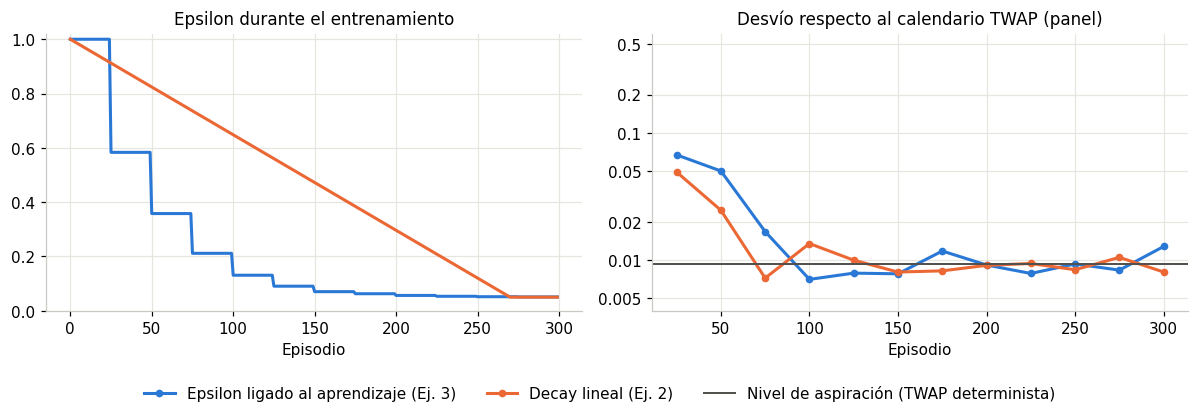

,Epsilon ligado al aprendizaje (Ej. 3),Decay lineal (Ej. 2)
episodio en que el desvío baja de 2 × TWAP,75,75
"episodio en que epsilon baja de 0,10",125,256
epsilon medio del entrenamiento,0.23,0.48
"desvío medio, 4 últimas medidas",0.010,0.009


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(hist3["epsilons"], color=COLOR["ddqn"])
axes[0].plot(hist2["epsilons"], color=COLOR["alt"])
axes[0].set(title="Epsilon durante el entrenamiento", xlabel="Episodio", ylim=(0, 1.02))
axes[1].plot(hist3["eval_episode"], hist3["dev"], color=COLOR["ddqn"], marker="o", ms=4, label="Epsilon ligado al aprendizaje (Ej. 3)")
axes[1].plot(hist2["eval_episode"], hist2["dev"], color=COLOR["alt"], marker="o", ms=4, label="Decay lineal (Ej. 2)")
axes[1].axhline(DEV_TWAP, color=COLOR["twap"], lw=1.3, label="Nivel de aspiración (TWAP determinista)")
axes[1].set(title="Desvío respecto al calendario TWAP (panel)", xlabel="Episodio")
dev_axis(axes[1])
legend_below(fig, axes[1])
plt.show()

def episodes_to(hist, level):
    # Primer episodio en el que el desvío medido baja de `level`
    hits = [ep for ep, dev in zip(hist["eval_episode"], hist["dev"]) if dev <= level]
    return hits[0] if hits else None

def episodes_below_eps(hist, level=0.10):
    hits = [i for i, e in enumerate(hist["epsilons"]) if e <= level]
    return hits[0] if hits else None

def resumen_exploracion(hist):
    ep_dev, ep_eps = episodes_to(hist, 2 * DEV_TWAP), episodes_below_eps(hist)
    return {
        "episodio en que el desvío baja de 2 × TWAP": ep_dev if ep_dev is not None else "no se alcanza",
        "episodio en que epsilon baja de 0,10": ep_eps if ep_eps is not None else "no se alcanza",
        "epsilon medio del entrenamiento": f"{np.mean(hist['epsilons']):.2f}",
        "desvío medio, 4 últimas medidas": f"{np.mean(hist['dev'][-4:]):.3f}",
    }

display(pd.DataFrame({
    "Epsilon ligado al aprendizaje (Ej. 3)": resumen_exploracion(hist3),
    "Decay lineal (Ej. 2)": resumen_exploracion(hist2),
}))

## 3.1 Lectura

- Con la regla nueva, epsilon cae en cuanto el agente se acerca al nivel de aspiración y se queda en el mínimo mientras se mantiene ahí. No hay que decidir de antemano cuántos episodios de exploración hacen falta.
- El decay lineal sigue explorando durante la mayor parte del entrenamiento aunque el agente ya haya alcanzado el objetivo: esa exploración ya no aporta.
- El resultado final es similar en ambos casos; lo que cambia es que la exploración se gasta solo mientras hace falta. La última política puede oscilar ligeramente al no conservar el mejor modelo: es lo que resuelve el guardado del Ejercicio 4, que usa esta misma señal para elegir el mejor modelo y decidir cuándo parar.

---
# Ejercicio 4. Mejoras sobre los ejercicios 2 y 3

Se desarrollan dos de las ideas propuestas: la **Idea B** sobre la reward del Ejercicio 2 y la **Idea C** sobre el entrenamiento del Ejercicio 3. Las dos se aplican en un único entrenamiento.

## 4.1 Idea B: margen del 10 % y volumen pendiente

**Consumir en torno al 90 % de la duración.** Se comprime el calendario objetivo: el plan termina en el 90 % de los bins, y el agente va retrasado si su volumen restante es mayor o igual que el tiempo restante de ese plan. La reward es la del Ejercicio 2 con el calendario nuevo. No hace falta tocar el estado, porque la frontera sigue siendo una recta en (tiempo restante, volumen restante).

**No dejar volumen pendiente.** Si el episodio termina por tiempo, se añade una *done reward* de −κ × fracción de la orden sin ejecutar.

**Calibración de κ.** Dos condiciones:

- *Por abajo:* dejar un título sin comprar ahorra su coste. La penalización por título, κ/V, tiene que superarlo con margen en todo el rango de tamaños.
- *Por arriba:* la penalización máxima es κ (orden sin ejecutar). Debe quedar en la escala del resto de recompensas para no desestabilizar los *targets* de la red.

Con **κ = 1** la penalización queda en [−1, 0] y se cumplen las dos, como muestra la tabla.

In [24]:
TARGET_90 = 0.9     # fracción de la duración en la que debe completarse la orden
KAPPA = 1.0         # penalización final por orden sin ejecutar


class EnvTWAP90(EnvTWAP):
    # --- Ejercicio 4, Idea B: bloque modificado ---
    target = TARGET_90

    def _compute_done_reward(self) -> float:
        vol_pending = (self.vol_care - self.exec_vol) / self.vol_care
        return -KAPPA * vol_pending


# Calibración: órdenes más pequeña, central y más grande del rango
saving = BUY_COST + abs(PRICE_MEAN) + 2 * PRICE_STD     # ahorro por no comprar un título, con margen de 2 desviaciones
rows = []
for T, V in [(400, 30), (500, 50), (600, 75)]:
    plan = {}
    for kappa in (0.0, KAPPA):
        Q = optimal_q(T, V, GAMMA, target=TARGET_90, kappa=kappa)
        optimal = lambda states, Q=Q: np.array(
            [Q[int(round(T * (1 - tl))), int(round(V * (1 - vl)))].argmax() for tl, vl in states])
        plan[kappa] = schedule_metrics(rollout_schedules(optimal, [T], [V]), [T], [V], TARGET_90).iloc[0]
        # Ventaja de comprar frente a esperar en el último bin con un título pendiente
        plan[kappa, "adv"] = Q[T - 1, V - 1, 1] - Q[T - 1, V - 1, 0]
    rows.append({
        "T": T, "V": V,
        "penalización por título (κ/V)": KAPPA / V,
        "ahorro por no comprarlo": saving,
        "ventaja de comprar en el último bin, sin κ": plan[0.0, "adv"],
        "ventaja de comprar en el último bin, con κ": plan[KAPPA, "adv"],
        "política óptima: orden completa": plan[KAPPA]["completado"] >= 1,
        "política óptima: tiempo usado": plan[KAPPA]["tiempo_usado"],
    })
display(pd.DataFrame(rows).set_index(["T", "V"]).style.format({
    "penalización por título (κ/V)": "{:.4f}", "ahorro por no comprarlo": "{:.4f}",
    "ventaja de comprar en el último bin, sin κ": "{:.4f}", "ventaja de comprar en el último bin, con κ": "{:.4f}",
    "política óptima: tiempo usado": "{:.1%}"}))

,,penalización por título (κ/V),ahorro por no comprarlo,"ventaja de comprar en el último bin, sin κ","ventaja de comprar en el último bin, con κ",política óptima: orden completa,política óptima: tiempo usado
T,V,,,,,,
400,30,0.0333,0.0083,0.0147,0.0480,True,87.2%
500,50,0.0200,0.0083,0.0147,0.0347,True,88.4%
600,75,0.0133,0.0083,0.0147,0.0280,True,89.0%


- La penalización por título supera al ahorro en todo el rango, incluso en la orden más grande.
- La penalización por retraso ya hace que completar sea óptimo. La *done reward* refuerza esa señal donde importa, en los últimos bins: la ventaja de comprar el título pendiente aumenta de forma clara respecto a no tenerla.
- La política óptima exacta con esta reward completa la orden y termina cerca del 90 % de la duración. Es el comportamiento que debe aprender el agente.

## 4.2 Idea C: parada, guardado y reanudación

**Guardado periódico.** Cada 25 episodios se escribe en disco todo lo necesario para continuar: pesos de las dos redes, estado del optimizador, epsilon, buffer, contadores, historial y estado del generador aleatorio (`checkpoints/ej4/last_*`).

**Mejor modelo.** Cuando el desvío del panel mejora y todas sus órdenes se completan, los pesos se guardan aparte (`best_*`). El criterio no tiene ruido muestral, así que el mejor modelo no es un golpe de suerte.

**Parada ligada al aprendizaje.** Se usa la misma señal que mueve epsilon:

- *Objetivo alcanzado:* desvío ≤ nivel de aspiración + 0,005, con todas las órdenes completas, durante 3 medidas seguidas.
- *Estancamiento:* 8 medidas sin mejorar el mejor desvío.
- *Tope:* 400 episodios.

Al terminar se restauran los pesos del mejor modelo. Para comprobar la reanudación, el entrenamiento se hace en dos sesiones: la primera se corta a los 50 episodios y la segunda arranca con un agente nuevo que carga el último guardado.

In [25]:
CKPT_DIR = Path("checkpoints/ej4")
CKPT_DIR.mkdir(parents=True, exist_ok=True)

DEV_TOL = 0.005     # margen sobre el nivel de aspiración
PATIENCE = 3        # medidas seguidas en el objetivo para parar
STALL = 8           # medidas sin mejorar para parar por estancamiento
MAX_EPISODES = 400


def save_checkpoint(agent, state, tag="last"):
    # --- Ejercicio 4, Idea C ---
    agent.primary_model.save_weights(str(CKPT_DIR / f"{tag}_primary.weights.h5"))
    agent.target_model.save_weights(str(CKPT_DIR / f"{tag}_target.weights.h5"))
    with open(CKPT_DIR / f"{tag}_state.pkl", "wb") as f:
        pickle.dump({"state": state, "epsilon": agent.epsilon, "buffer": list(agent.buffer),
                     "rng": np.random.get_state()}, f)


def load_checkpoint(agent, tag="last"):
    # Deja al agente y al generador aleatorio como estaban al guardar; devuelve el estado del entrenamiento
    # El optimizador se construye antes para que también se recuperen sus variables (momentos de Adam)
    agent.primary_model.optimizer.build(agent.primary_model.trainable_variables)
    agent.primary_model.load_weights(str(CKPT_DIR / f"{tag}_primary.weights.h5"))
    agent.target_model.load_weights(str(CKPT_DIR / f"{tag}_target.weights.h5"))
    with open(CKPT_DIR / f"{tag}_state.pkl", "rb") as f:
        ckpt = pickle.load(f)
    agent.epsilon = ckpt["epsilon"]
    agent.buffer = deque(ckpt["buffer"], maxlen=agent.buffer_size)
    np.random.set_state(ckpt["rng"])
    return ckpt["state"]


def stop_and_checkpoint(target):
    dev_goal = panel_deviation(twap_policy(target), target)[0]
    def on_eval(agent, state):
        dev, completed = state["dev"][-1], state["completed"][-1]
        # 1) Mejor modelo hasta ahora
        if completed == 1 and dev < state.get("best_dev", np.inf):
            state["best_dev"], state["best_episode"], state["since_best"] = dev, state["episode"], 0
            agent.primary_model.save_weights(str(CKPT_DIR / "best_primary.weights.h5"))
        else:
            state["since_best"] = state.get("since_best", 0) + 1
        # 2) Condiciones de parada ligadas al aprendizaje
        on_goal = completed == 1 and dev <= dev_goal + DEV_TOL
        state["goal_streak"] = state.get("goal_streak", 0) + 1 if on_goal else 0
        if state["goal_streak"] >= PATIENCE:
            state["stop_reason"] = "objetivo alcanzado"
        elif state["since_best"] >= STALL:
            state["stop_reason"] = "estancamiento"
        # 3) Guardado periódico
        save_checkpoint(agent, state)
        return "stop_reason" in state
    return on_eval

In [26]:
# Sesión 1: se interrumpe a los 50 episodios
set_seed()
env4 = EnvTWAP90(data, 60)
agent4 = make_agent(env4, GAMMA)
fill_buffer(agent4, env4)
state4 = train_agent(agent4, env4, 50, adaptive_epsilon(TARGET_90), target=TARGET_90,
                     on_eval=stop_and_checkpoint(TARGET_90))
print(f"Sesión 1 interrumpida en el episodio {state4['episode']} | epsilon {agent4.epsilon:.3f} | "
      f"desvío {state4['dev'][-1]:.4f}")

Episodio  50 | desvío 0.033 | órdenes completas 100% | epsilon 0.33 | pérdida 3.1e-06
Sesión 1 interrumpida en el episodio 50 | epsilon 0.331 | desvío 0.0334


In [27]:
# Sesión 2: agente nuevo que continúa desde el último guardado
agent4 = make_agent(env4, GAMMA)
dev_new = panel_deviation(greedy_policy(agent4), TARGET_90)[0]
state4 = load_checkpoint(agent4)
dev_loaded = panel_deviation(greedy_policy(agent4), TARGET_90)[0]
print(f"Agente nuevo sin entrenar: desvío {dev_new:.4f}")
print(f"Tras cargar el guardado:   desvío {dev_loaded:.4f} (último medido en la sesión 1: {state4['dev'][-1]:.4f}) | "
      f"episodio {state4['episode']} | epsilon {agent4.epsilon:.3f} | buffer {len(agent4.buffer):,} experiencias\n")

state4 = train_agent(agent4, env4, MAX_EPISODES, adaptive_epsilon(TARGET_90), target=TARGET_90,
                     state=state4, on_eval=stop_and_checkpoint(TARGET_90))
state4.setdefault("stop_reason", "tope de episodios")

# Se restauran los pesos del mejor modelo
if "best_episode" in state4:
    agent4.primary_model.load_weights(str(CKPT_DIR / "best_primary.weights.h5"))
print(f"\nParada en el episodio {state4['episode']} por: {state4['stop_reason']}")
print(f"Mejor modelo: episodio {state4.get('best_episode')} con desvío {state4.get('best_dev', np.nan):.4f} "
      f"(nivel de aspiración {panel_deviation(twap_policy(TARGET_90), TARGET_90)[0]:.4f})")

Agente nuevo sin entrenar: desvío 0.5300
Tras cargar el guardado:   desvío 0.0334 (último medido en la sesión 1: 0.0334) | episodio 50 | epsilon 0.331 | buffer 30,000 experiencias

Episodio 100 | desvío 0.006 | órdenes completas 100% | epsilon 0.13 | pérdida 1.2e-06
Episodio 150 | desvío 0.006 | órdenes completas 100% | epsilon 0.07 | pérdida 4.6e-06

Parada en el episodio 150 por: objetivo alcanzado
Mejor modelo: episodio 125 con desvío 0.0053 (nivel de aspiración 0.0079)


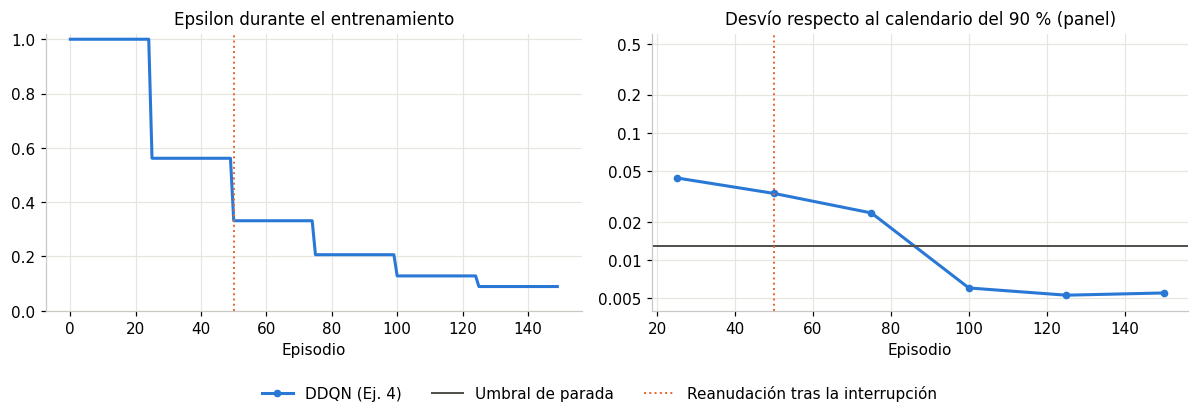

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(state4["epsilons"], color=COLOR["ddqn"])
axes[0].set(title="Epsilon durante el entrenamiento", xlabel="Episodio", ylim=(0, 1.02))
axes[1].plot(state4["eval_episode"], state4["dev"], color=COLOR["ddqn"], marker="o", ms=4, label="DDQN (Ej. 4)")
axes[1].axhline(panel_deviation(twap_policy(TARGET_90), TARGET_90)[0] + DEV_TOL, color=COLOR["twap"], lw=1.3,
                label="Umbral de parada")
axes[1].set(title="Desvío respecto al calendario del 90 % (panel)", xlabel="Episodio")
dev_axis(axes[1])
for ax in axes:
    ax.axvline(50, color=COLOR["alt"], lw=1.3, ls=":", label="Reanudación tras la interrupción")
legend_below(fig, axes[1])
plt.show()

## 4.3 Resultados

La estabilidad se comprueba sobre 300 episodios de test, que el agente no ha visto: proporción de órdenes completas y distribución del tiempo consumido. La referencia es la regla TWAP con el calendario del 90 %.

,órdenes completas,tiempo usado: media,tiempo usado: percentil 5,tiempo usado: percentil 95,desvío respecto al plan del 90 %
DDQN (Ejercicio 4),100%,89.3%,88.9%,89.7%,0.005
Regla TWAP al 90 %,100%,88.4%,87.8%,88.9%,0.008


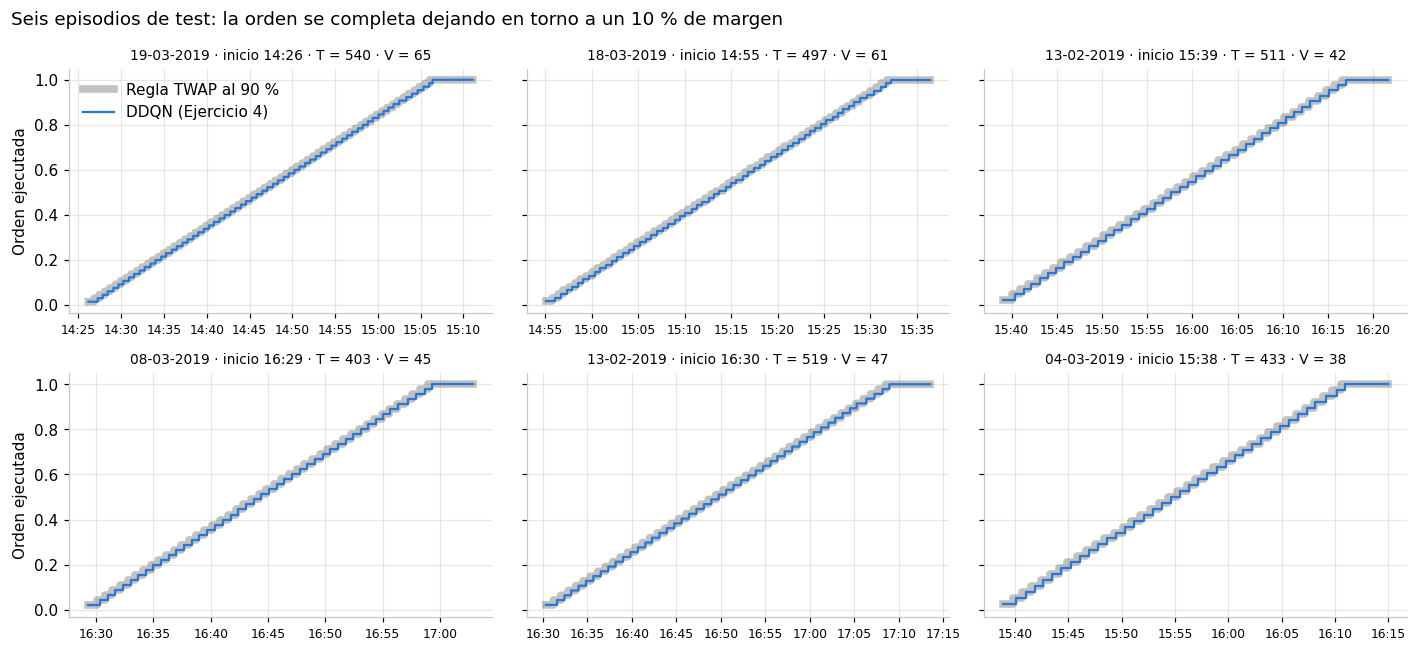

In [29]:
episodes_test = sample_episodes(dict_["test"], 300, seed=2025)
m4, buys4 = evaluate(greedy_policy(agent4), episodes_test, TARGET_90)
m_twap90, buys_twap90 = evaluate(twap_policy(TARGET_90), episodes_test, TARGET_90)

estabilidad = pd.DataFrame({
    nombre: {
        "órdenes completas": (m["completado"] >= 1).mean(),
        "tiempo usado: media": m["tiempo_usado"].mean(),
        "tiempo usado: percentil 5": m["tiempo_usado"].quantile(0.05),
        "tiempo usado: percentil 95": m["tiempo_usado"].quantile(0.95),
        "desvío respecto al plan del 90 %": m["desvio"].mean(),
    } for nombre, m in [("DDQN (Ejercicio 4)", m4), ("Regla TWAP al 90 %", m_twap90)]
}).T
display(estabilidad.style.format({"órdenes completas": "{:.0%}", "tiempo usado: media": "{:.1%}",
                                  "tiempo usado: percentil 5": "{:.1%}", "tiempo usado: percentil 95": "{:.1%}",
                                  "desvío respecto al plan del 90 %": "{:.3f}"}))

plot_schedules(episodes_test, "DDQN (Ejercicio 4)", buys4, "Regla TWAP al 90 %", buys_twap90,
               title="Seis episodios de test: la orden se completa dejando en torno a un 10 % de margen")

## 4.4 Lectura

- **Idea B.** El agente completa las órdenes y termina en torno al 90 % de la duración, con poca variación entre episodios. El margen queda disponible para absorber un retraso.
- **Idea C.** La reanudación devuelve al agente exactamente al punto guardado: el desvío tras cargar coincide con el último medido. El entrenamiento se detiene por el criterio de aprendizaje, sin agotar el tope de episodios.
- La señal que mide el aprendizaje sirve para las tres cosas: mover epsilon, elegir el mejor modelo y decidir cuándo parar.

---
# Comparación final en test

Todos los agentes se evalúan sin exploración sobre **los mismos 300 episodios de test**. Al ser una comparación pareada, la diferencia de *slippage* frente al TWAP se mide episodio a episodio y su error estándar es mucho menor que el de dos muestras independientes.

- **Desvío**: respecto al calendario objetivo de cada agente (100 % de la duración, o 90 % en el Ejercicio 4).
- **Desfase**: bins de diferencia, de media, entre cada compra del agente y la compra equivalente de la regla TWAP con el mismo calendario. Positivo es comprar más tarde. La regla compra al inicio de cada tramo, así que un desfase de pocos bins sigue siendo un calendario regular.
- **Slippage**: pb frente al VWAP de mercado; positivo es comprar más caro.

In [30]:
def mean_lag(buys, buys_ref):
    # Desfase medio (en bins) entre cada compra y la compra equivalente del calendario de referencia
    lags = []
    for b, ref in zip(buys, buys_ref):
        pos, pos_ref = np.flatnonzero(b), np.flatnonzero(ref)
        n = min(len(pos), len(pos_ref))
        lags.append((pos[:n] - pos_ref[:n]).mean())
    return np.mean(lags)


m_twap, buys_twap = evaluate(twap_policy(), episodes_test)
agentes = {
    "TWAP determinista": (twap_policy(), 1.0, buys_twap),
    "Ej. 1: DDQN, reward por defecto": (greedy_policy(agent), 1.0, buys_twap),
    "Ej. 2: DDQN, reward TWAP": (greedy_policy(agent2), 1.0, buys_twap),
    "Ej. 3: DDQN, epsilon ligado al aprendizaje": (greedy_policy(agent3), 1.0, buys_twap),
    "Ej. 4: DDQN, plan del 90 %": (greedy_policy(agent4), TARGET_90, buys_twap90),
}

rows, compras = {}, {}
for nombre, (policy, target, buys_ref) in agentes.items():
    m, buys = evaluate(policy, episodes_test, target)
    compras[nombre] = buys
    diff = m["slippage_pb"] - m_twap["slippage_pb"]         # pareada: mismo episodio
    rows[nombre] = {
        "plan": f"{target:.0%}",
        "órdenes completas": (m["completado"] >= 1).mean(),
        "tiempo usado": m["tiempo_usado"].mean(),
        "desvío": m["desvio"].mean(),
        "desfase (bins)": mean_lag(buys, buys_ref),
        "slippage medio (pb)": m["slippage_pb"].mean(),
        "slippage desv. (pb)": m["slippage_pb"].std(),
        "dif. vs TWAP (pb)": diff.mean(),
        "error estándar (pb)": diff.std() / np.sqrt(len(diff)),
    }
tabla_final = pd.DataFrame(rows).T
display(tabla_final.style.format({
    "órdenes completas": "{:.0%}", "tiempo usado": "{:.1%}", "desvío": "{:.3f}", "desfase (bins)": "{:+.1f}",
    "slippage medio (pb)": "{:+.2f}", "slippage desv. (pb)": "{:.2f}", "dif. vs TWAP (pb)": "{:+.2f}",
    "error estándar (pb)": "{:.2f}"}))

,plan,órdenes completas,tiempo usado,desvío,desfase (bins),slippage medio (pb),slippage desv. (pb),dif. vs TWAP (pb),error estándar (pb)
TWAP determinista,100%,100%,98.2%,0.009,+0.0,+2.26,3.86,+0.00,0.00
"Ej. 1: DDQN, reward por defecto",100%,0%,75.5%,0.268,-144.7,+2.24,9.97,-0.03,0.53
"Ej. 2: DDQN, reward TWAP",100%,100%,98.3%,0.008,+0.6,+2.26,3.85,-0.00,0.01
"Ej. 3: DDQN, epsilon ligado al aprendizaje",100%,100%,98.2%,0.013,-2.0,+2.27,3.86,+0.00,0.02
"Ej. 4: DDQN, plan del 90 %",90%,100%,89.3%,0.005,+3.6,+2.21,4.18,-0.05,0.07


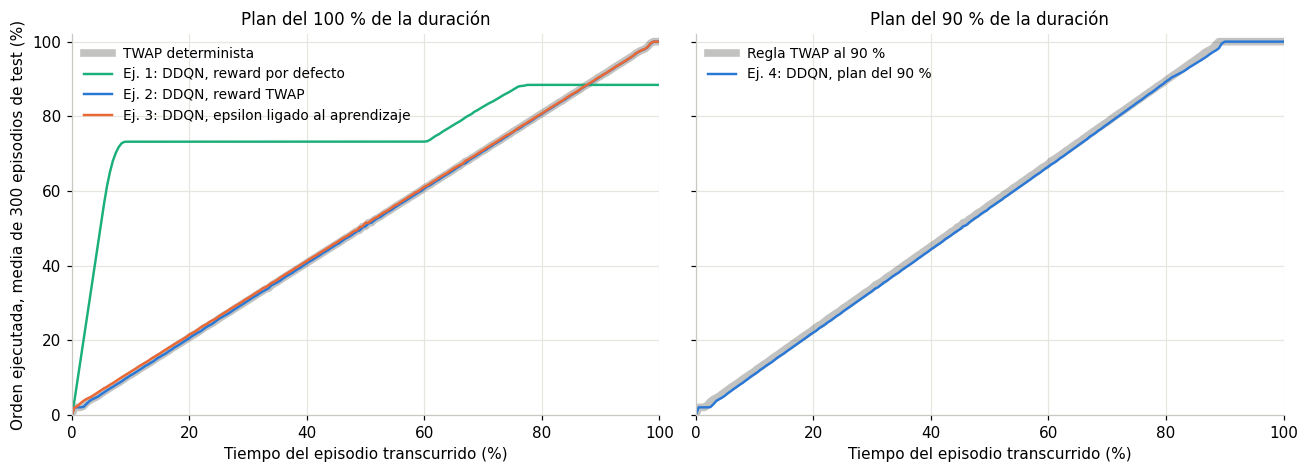

In [31]:
T_test = np.array([e["T"] for e in episodes_test])
V_test = np.array([e["V"] for e in episodes_test])
grid = np.linspace(0, 1, 201)
paneles = [
    ("Plan del 100 % de la duración", {
        "Ej. 1: DDQN, reward por defecto": COLOR["aux"],
        "Ej. 2: DDQN, reward TWAP": COLOR["ddqn"],
        "Ej. 3: DDQN, epsilon ligado al aprendizaje": COLOR["alt"],
    }, buys_twap, "TWAP determinista"),
    ("Plan del 90 % de la duración", {"Ej. 4: DDQN, plan del 90 %": COLOR["ddqn"]}, buys_twap90, "Regla TWAP al 90 %"),
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (titulo, series, buys_ref, nombre_ref) in zip(axes, paneles):
    ax.plot(grid * 100, mean_trajectory(buys_ref, T_test, V_test, grid) * 100, color=COLOR["twap"], lw=5, alpha=0.35,
            label=nombre_ref)
    for nombre, color in series.items():
        ax.plot(grid * 100, mean_trajectory(compras[nombre], T_test, V_test, grid) * 100, color=color, lw=1.6, label=nombre)
    ax.set(title=titulo, xlabel="Tiempo del episodio transcurrido (%)", xlim=(0, 100), ylim=(0, 102))
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("Orden ejecutada, media de 300 episodios de test (%)")
plt.tight_layout()
plt.show()

# Conclusiones

1. **Entorno (Ej. 1).** El simulador y el DDQN entrenan y ejecutan de principio a fin. La reward por defecto no define un calendario ni obliga a completar la orden, y el agente resultante lo refleja.
2. **TWAP (Ej. 2).** Una reward con dos piezas, coste por compra y penalización por retraso, reproduce el calendario TWAP cuando se combina con descuento. El agente completa las órdenes y su desvío es del orden del que impone la discretización, en todo el rango de duraciones y tamaños. Gamma se elige con un criterio cuantitativo (la ventaja de la acción correcta debe superar el ruido de la reward) y el contraste con 0,99 lo respalda.
3. **Exploración (Ej. 3).** Epsilon ligado a la distancia al nivel de aspiración deja de depender del nº de episodios: baja cuando el agente alcanza el objetivo y no antes.
4. **Mejoras (Ej. 4).** Comprimir el calendario al 90 % y penalizar el volumen pendiente da órdenes completas con margen. El entrenamiento se guarda, se reanuda y se detiene con la misma señal de aprendizaje.
5. **Precio.** Los agentes tipo TWAP tienen el mismo *slippage* que el TWAP determinista: la diferencia pareada no se distingue de cero. Es el resultado correcto para una réplica, porque el estado no contiene información de mercado.

**Limitaciones.** El simulador no modela impacto de mercado y compra siempre al ask. La red no reproduce la frontera exacta de la regla: sus compras quedan desplazadas unos pocos bins (columna de desfase). El calendario es igual de regular, pero el agente no exprime la reward al máximo. Mejorar el precio frente al TWAP exigiría añadir al estado variables del libro de órdenes o de tendencia.